# 01 · Freeze the pilot dataset (`pilot_v1`)

Turns the output of the v2 reference notebook into the **final, versioned training set** for the multimodal pipeline.
Nothing here calls a model, so it runs on a CPU runtime in a minute or two.

What "frozen" means here:
- every sample is a **(target photo, sketch, reference, caption)** quadruple, all resized to one resolution and **spatially aligned**
- only samples that passed the reference filters *and* have a trustworthy segmentation are kept, unless you approve them by eye below
- the split is **by photo** with a fixed seed, and the split is written into the data
- every row already carries the role tags from the presentation (`sketch→geometry, text→semantics, reference→appearance`) and a `conflict_type` field (`none` for now) so the conflict subset slots in later without changing the format
- one zip on Drive (`pilot_v1.zip`) + a manifest with counts and a hash

**Run order:** config → load → look at the three contact sheets → fill in the decision sets → everything after that is automatic.

In [ ]:
import os, json, glob, hashlib, shutil, zipfile, base64, io, datetime
from collections import Counter
import numpy as np, pandas as pd
from PIL import Image
from IPython.display import HTML, display
from google.colab import drive
drive.mount('/content/drive')

ROOT       = '/content/drive/MyDrive/sketchy_dataset_one_sketch'
CSV_IN     = f'{ROOT}/sketchy_captions_sample.csv'   # original photo/sketch paths + captions
FINAL_CSV  = f'{ROOT}/sketchy_with_refs_v2.csv'      # output of the v2 reference notebook
BACKUP_ZIP = f'{ROOT}/ref_v2_backup.zip'             # holds reference images + masks if the runtime was reset
OUT        = '/content/pilot_v1'
OUT_ZIP    = f'{ROOT}/pilot_v1.zip'
RES, SEED  = 512, 0                                  # 512 = the resolution UniCombine/OminiControl are trained at
VAL_FRAC, TEST_FRAC = 0.10, 0.10

Mounted at /content/drive


## Load, join and restore files
`sketchy_with_refs_v2.csv` was saved without the row id and with local Colab paths, so this re-joins it to the original CSV by row order (and **asserts** the two agree on category and caption before trusting that). Reference images and masks are pulled back out of `ref_v2_backup.zip` if the local disk was wiped.

In [ ]:
src   = pd.read_csv(CSV_IN)
final = pd.read_csv(FINAL_CSV)
assert len(src) == len(final), (len(src), len(final))
assert (src.category.astype(str).values == final.category.astype(str).values).all(), 'row order differs between the two CSVs'
if 'caption' in final.columns:
    assert (src.caption.astype(str).values == final.caption.astype(str).values).all(), 'captions differ -> row order mismatch'

df = final.copy()
df['row']         = np.arange(len(df))
df['photo_file']  = src.image_path.values      # original photos on Drive
df['sketch_file'] = src.sketch_path.values
for c in ['passed', 'seg_ok']:
    df[c] = df[c].astype(str).str.lower().eq('true')

RESTORE, _idx = '/content/ref_v2_restore', None
def locate(p):
    global _idx
    if isinstance(p, str) and os.path.exists(p):
        return p
    if _idx is None:
        if not os.path.exists(RESTORE):
            print('restoring from', BACKUP_ZIP); zipfile.ZipFile(BACKUP_ZIP).extractall(RESTORE)
        _idx = {os.path.basename(f): f for f in glob.glob(RESTORE + '/**/*', recursive=True) if os.path.isfile(f)}
    return _idx.get(os.path.basename(str(p)))

df['ref_file']  = df.ref_path.map(locate)
df['mask_file'] = df.mask_path.map(locate)
print('missing  photo:', int((~df.photo_file.map(os.path.exists)).sum()), '| sketch:', int((~df.sketch_file.map(os.path.exists)).sum()),
      '| reference:', int(df.ref_file.isna().sum()), '| mask:', int(df.mask_file.isna().sum()))
print(df.groupby(['passed', 'seg_ok']).size().rename('rows'))

restoring from /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
missing  photo: 0 | sketch: 0 | reference: 0 | mask: 0
passed  seg_ok
False   False       3
        True       15
True    False      23
        True      159
Name: rows, dtype: int64


## Look before you freeze
Three groups, most important first. Columns: photo | sketch | reference | metadata. Page through with the slice (`[20:40]`, ...).

1. **passed the filters but segmentation fell back to a centre crop** (`seg_ok=False`): the colour check and the VLM attributes were computed on a crop that may include background, so these "passes" are the least trustworthy.
2. **failed the filters**: some may still look fine (the multi-object check is a heuristic).
3. **random sample of the clean passes**: is the material actually visible, is it one clean object, does it avoid the target's shape?

23 passed but unverified segmentation


6,,,,"trumpet | seg=fallback_center | dino 0.13 | colour 0.13 | objects 1black and white / metal / shinyA person holds a shiny, silver French horn."
7,,,,lobster | seg=fallback_center | dino 0.03 | colour 0.21 | objects 1green and brown / nan / roughA large lobster with yellow bands on its claws.
9,,,,saxophone | seg=fallback_center | dino 0.12 | colour 0.34 | objects 1gold / metal / shinyMan plays golden saxophone with focused expression.
13,,,,"crab | seg=fallback_center | dino 0.10 | colour 0.21 | objects 1brown, tan and grey / nan / matteA brown crab with prominent claws on a rocky shore."
21,,,,"helicopter | seg=fallback_center | dino 0.15 | colour 0.34 | objects 1blue, white and red / metal / smoothHelicopter hovering above rooftop at sunset."
32,,,,"kangaroo | seg=fallback_center | dino 0.09 | colour 0.19 | objects 1brown, grey and beige / nan / matteA kangaroo leaps over a fence."
38,,,,lobster | seg=fallback_center | dino 0.06 | colour 0.24 | objects 1brown and tan / nan / glossyA dark lobster with white bands on its claws.
45,,,,"pistol | seg=fallback_center | dino 0.12 | colour 0.26 | objects 1green, brown and yellow / wood / roughWoman aiming a black revolver at target."
46,,,,"blimp | seg=fallback_center | dino 0.02 | colour 0.36 | objects 1white and red / plastic / glossySanyo blimp on ground, red logo prominent."
61,,,,"mouse | seg=fallback_center | dino 0.12 | colour 0.27 | objects 1dark grey, black and brown / fur / fuzzyA dark mouse with large ears and whiskers, close-up."
94,,,,"crab | seg=fallback_center | dino 0.07 | colour 0.11 | objects 1brown, gray and green / nan / matteA crab with green seaweed on its shell."

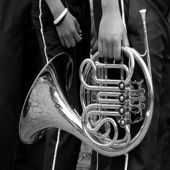
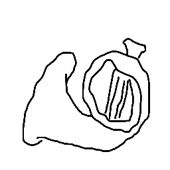
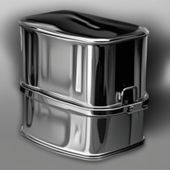
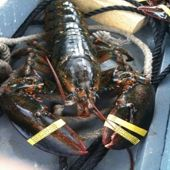
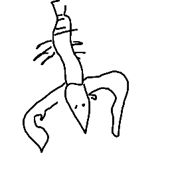
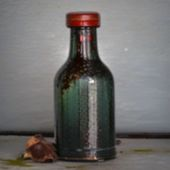
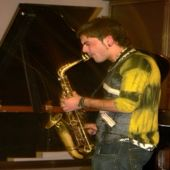
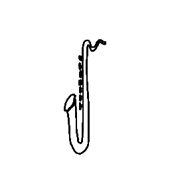
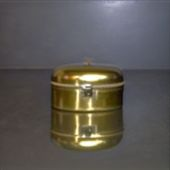
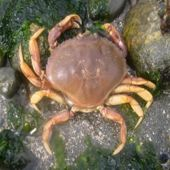
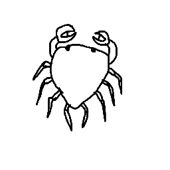
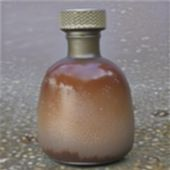
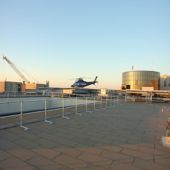
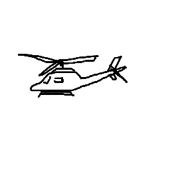
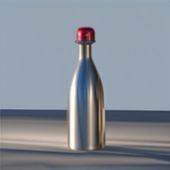
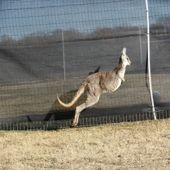
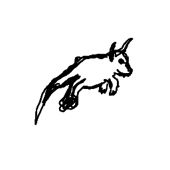
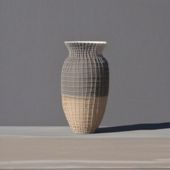
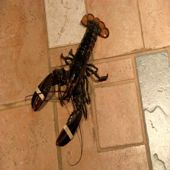
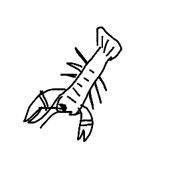
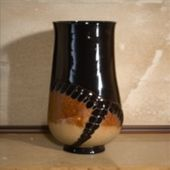
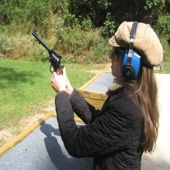
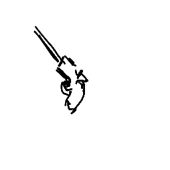
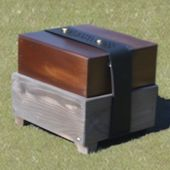
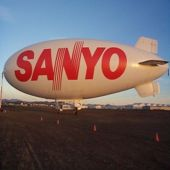
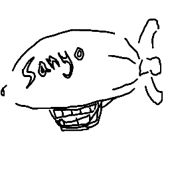
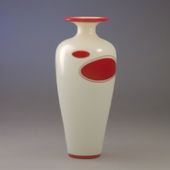
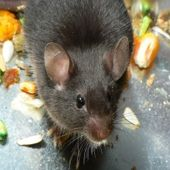
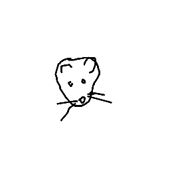
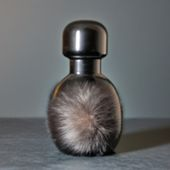
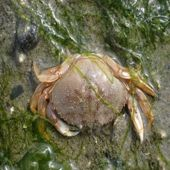
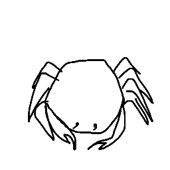
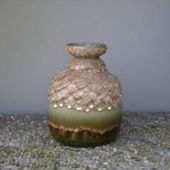
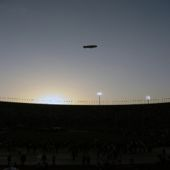
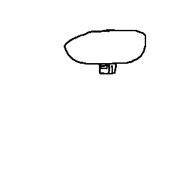
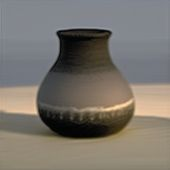
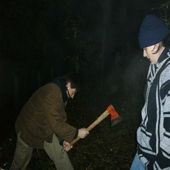
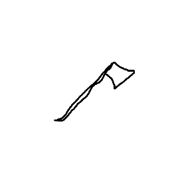
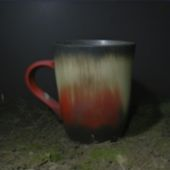
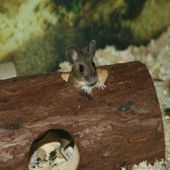
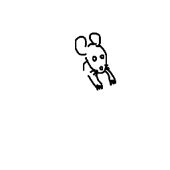
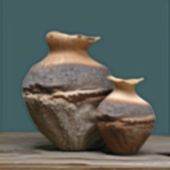
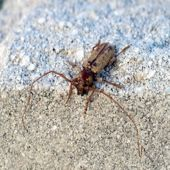
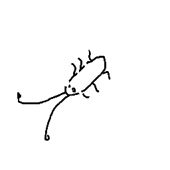
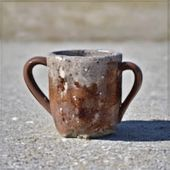
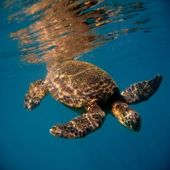
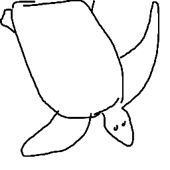
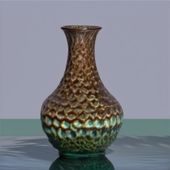
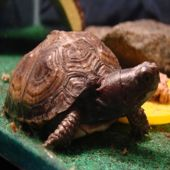
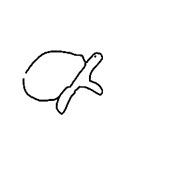
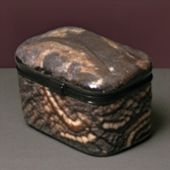
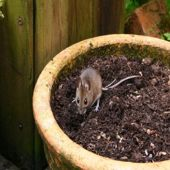
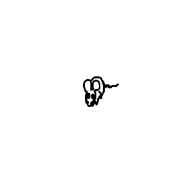
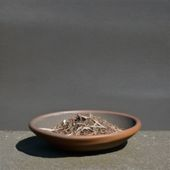
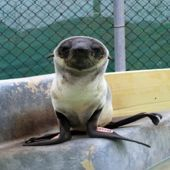
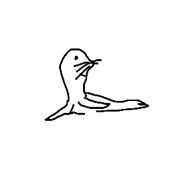
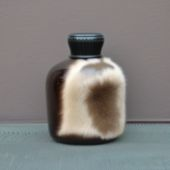
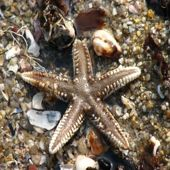
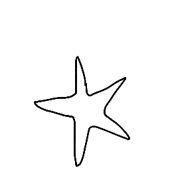
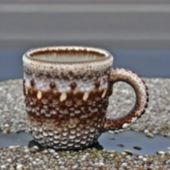

In [ ]:
def b64(path, size=170):
    im = Image.open(path).convert('RGB'); im.thumbnail((size, size))
    buf = io.BytesIO(); im.save(buf, 'JPEG', quality=80)
    return base64.b64encode(buf.getvalue()).decode()

def sheet(ids):
    html = ''
    for i in ids:
        r = df.loc[i]
        cells = ''.join(f"<td><img src='data:image/jpeg;base64,{b64(r[c])}'></td>" for c in ['photo_file', 'sketch_file', 'ref_file'])
        html += (f"<tr><td style='padding:4px'><b>{r.row}</b></td>{cells}"
                 f"<td style='max-width:320px;padding:6px'><b>{r.category}</b> | seg={r.seg_method} | dino {r.dino_sim:.2f} | colour {r.color_dist:.2f} | objects {r.n_obj}<br>"
                 f"{r.colors} / {r.material} / {r.finish}<br><i>{str(r.caption)[:160]}</i></td></tr>")
    display(HTML(f'<table>{html}</table>'))

g1 = df.index[df.passed & ~df.seg_ok]
print(len(g1), 'passed but unverified segmentation'); sheet(g1[:20])

18 failed filters


10,,,,"fish | seg=clipseg+sam | dino 0.38 | colour 0.15 | objects 1brown, beige and white / nan / fuzzyA clownfish swims near a sea anemone."
22,,,,mushroom | seg=clipseg+sam | dino 0.30 | colour 0.20 | objects 1red and white / plastic / glossyRed mushroom with white spots on a leafy ground.
41,,,,"seagull | seg=clipseg+sam | dino 0.13 | colour 0.10 | objects 3white, grey and yellow / feathered / matteA seagull perched on a stone ledge, showcasing its white body and yellow beak."
42,,,,"bread | seg=clipseg+sam | dino 0.34 | colour 0.12 | objects 1golden, light brown and white / baked dough / texturedA rustic loaf of bread with a golden crust and diagonal slashes."
43,,,,couch | seg=clipseg+sam | dino 0.10 | colour 0.17 | objects 2light grey and white / fabric / matteSilver velvet couch with red blanket and green pillows.
68,,,,"turtle | seg=fallback_center | dino 0.25 | colour 0.17 | objects 1dark brown, yellow and black / shell / roughA turtle with a patterned shell and green leaves nearby."
76,,,,"hat | seg=clipseg+sam | dino 0.32 | colour 0.13 | objects 1light brown, blue and green / woven straw / texturedColorful band on woven straw hat."
85,,,,pistol | seg=fallback_center | dino 0.10 | colour 0.11 | objects 2green / metal / wornVintage revolver with open cylinder and textured grip.
99,,,,"teapot | seg=clipseg+sam | dino 0.30 | colour 0.21 | objects 1white, pink and green / ceramic / glossyWhite teapot with pink floral design, resting in grass."
122,,,,"candle | seg=clipseg+sam | dino 0.32 | colour 0.22 | objects 1orange, yellow and white / wax / smoothA glowing candle in a glass holder on a wooden table."
161,,,,bee | seg=fallback_center | dino 0.08 | colour 0.19 | objects 1nan / fabric / matteBee hovering near pink flowers.

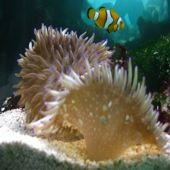
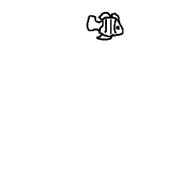
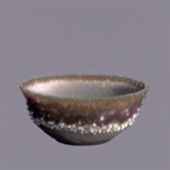
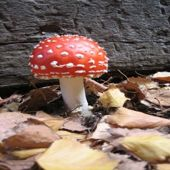
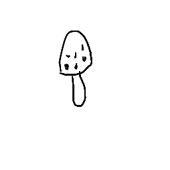
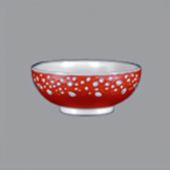
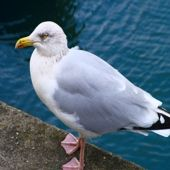
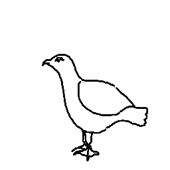
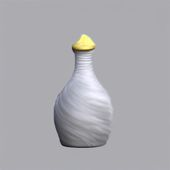
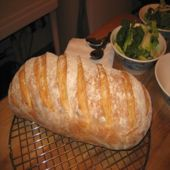
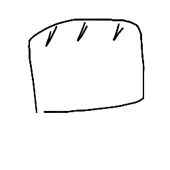
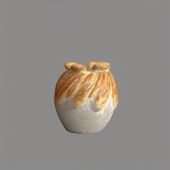
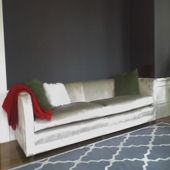
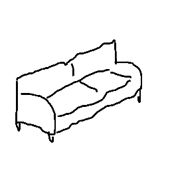
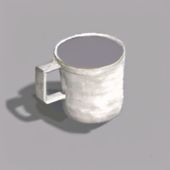
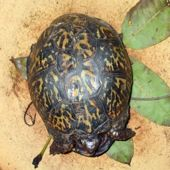
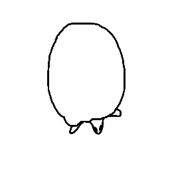
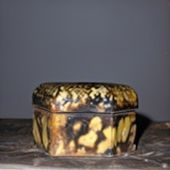
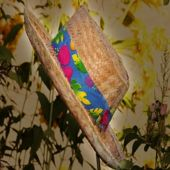
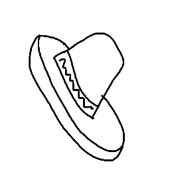
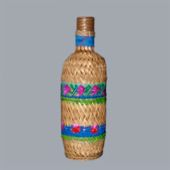
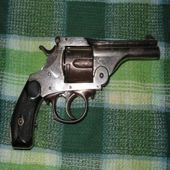
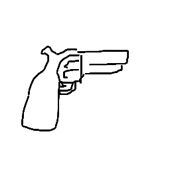
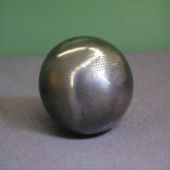
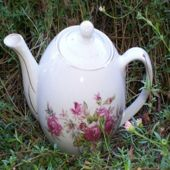
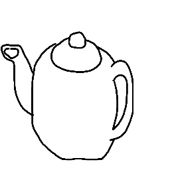
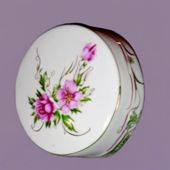
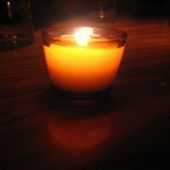
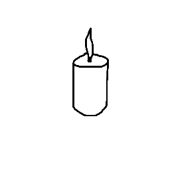
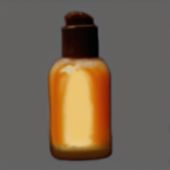
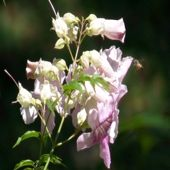
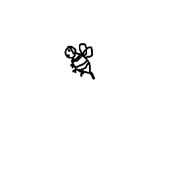
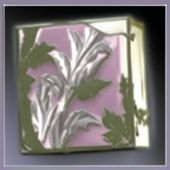
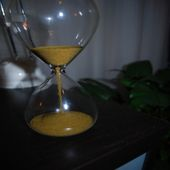
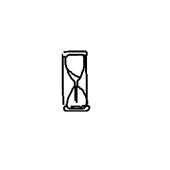
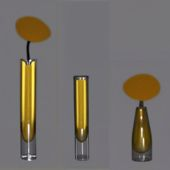
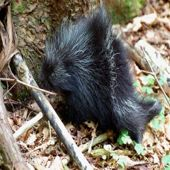
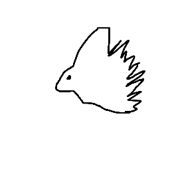
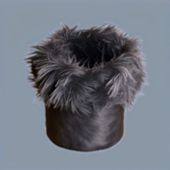
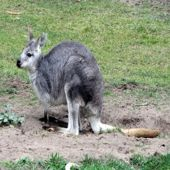
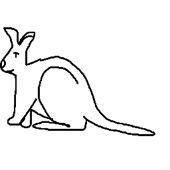
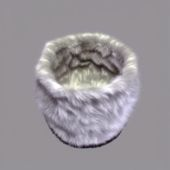
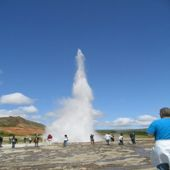
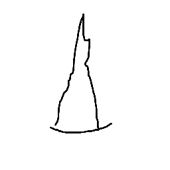
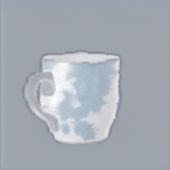
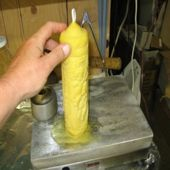
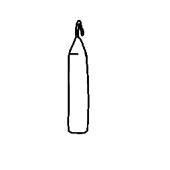
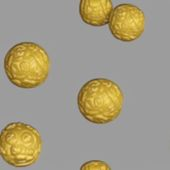
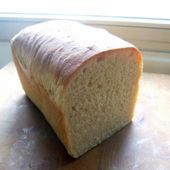
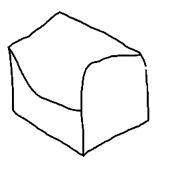
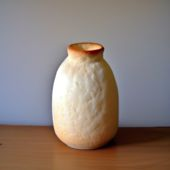
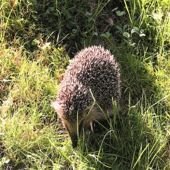
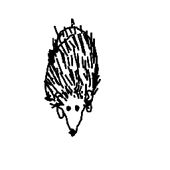
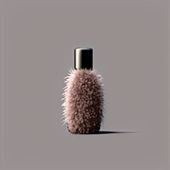

In [ ]:
g2 = df.index[~df.passed]
print(len(g2), 'failed filters'); sheet(g2[:20])

37,,,,rhinoceros | seg=clipseg+sam | dino 0.08 | colour 0.23 | objects 1gray and brown / nan / matteA rhinoceros grazes in a grassy field.
56,,,,"pear | seg=clipseg+sam | dino 0.16 | colour 0.23 | objects 1green, yellow and light brown / nan / matteA green pear hangs from a tree branch."
19,,,,lobster | seg=clipseg+sam | dino 0.16 | colour 0.30 | objects 1red and brown / nan / roughRed lobster with prominent claws in grass.
112,,,,"tiger | seg=clipseg+sam | dino 0.21 | colour 0.15 | objects 1orange, black and white / fur / smoothA tiger with striking stripes and intense gaze."
101,,,,"harp | seg=clipseg | dino 0.26 | colour 0.22 | objects 1light brown, gold and black / wood / glossyA woman plays a black harp with golden strings."
26,,,,"spoon | seg=clipseg+sam | dino 0.27 | colour 0.21 | objects 1silver, beige and brown / metal / shinySilver spoon with wooden handle on blue and white cloth."
58,,,,pistol | seg=clipseg | dino 0.23 | colour 0.12 | objects 1silver and black / metal / glossySilver revolver with open cylinder and black grip.
16,,,,"strawberry | seg=clipseg+sam | dino 0.27 | colour 0.27 | objects 1red, pink and orange / fruit / smoothA red strawberry with a green stem on a white background."
54,,,,"spoon | seg=clipseg+sam | dino 0.27 | colour 0.14 | objects 1brown, tan and light orange / wood / smoothWooden spoon with smooth, rounded bowl and handle."
118,,,,couch | seg=clipseg+sam | dino 0.11 | colour 0.27 | objects 1cream and red / leather / smoothA golden dog lounges on a white couch with red cushions.
110,,,,"lion | seg=clipseg+sam | dino 0.06 | colour 0.12 | objects 1tan, light brown and grey / fur / matteLion with intense gaze and prominent mane."

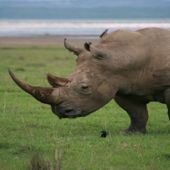
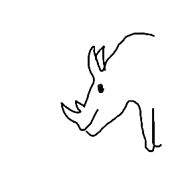
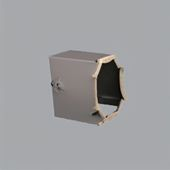
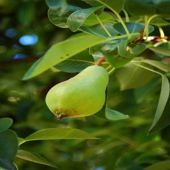
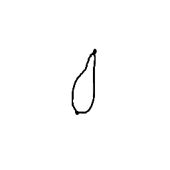
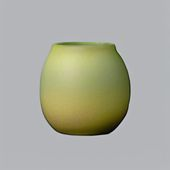
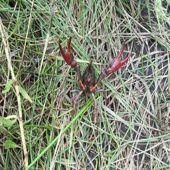
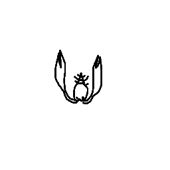
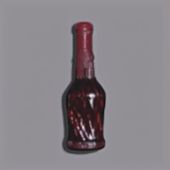
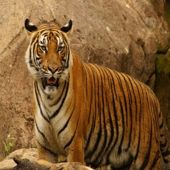
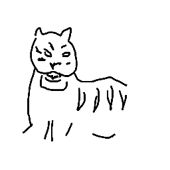
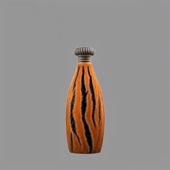
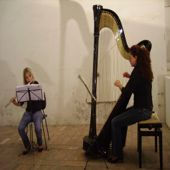
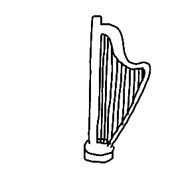
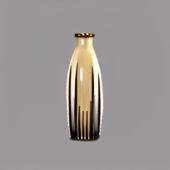
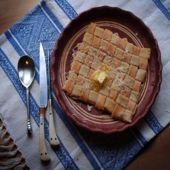
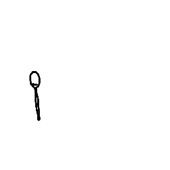
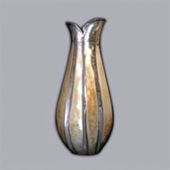
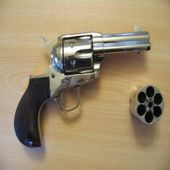
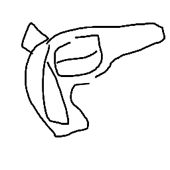
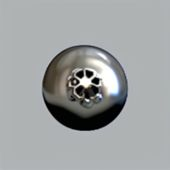
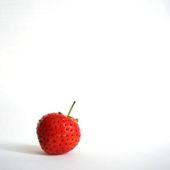
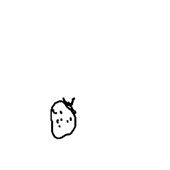
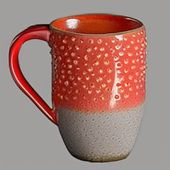
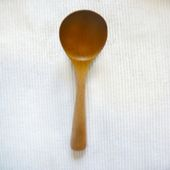
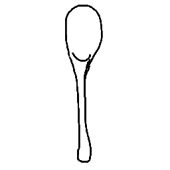
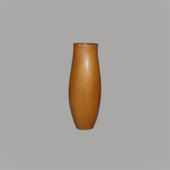
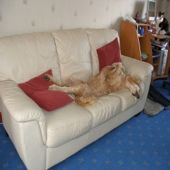
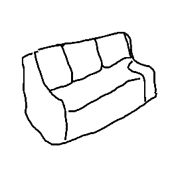
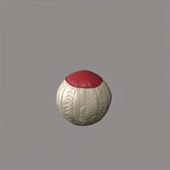
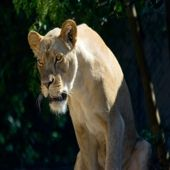
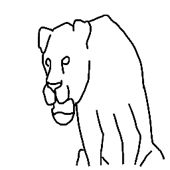
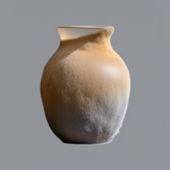
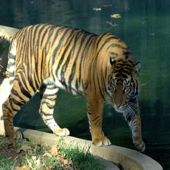
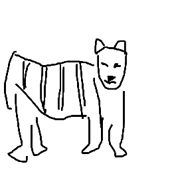
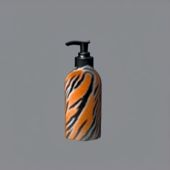
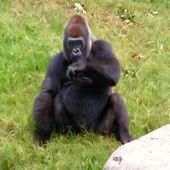
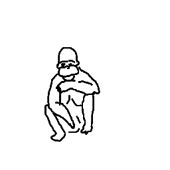
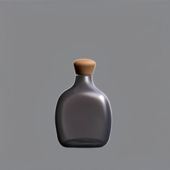
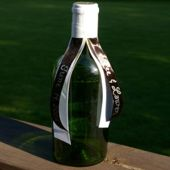
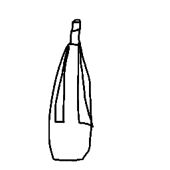
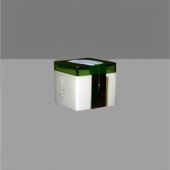
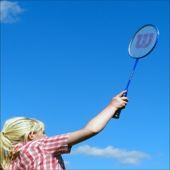
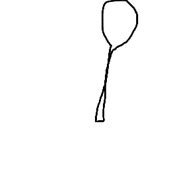
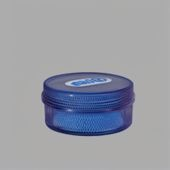
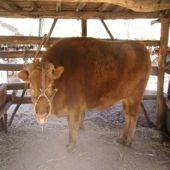
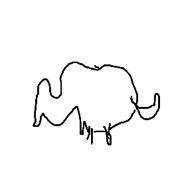
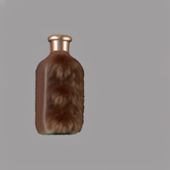
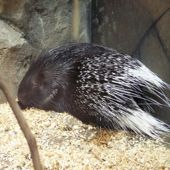
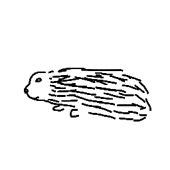
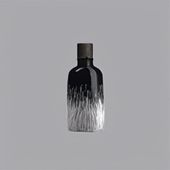
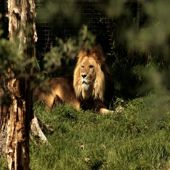
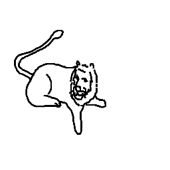
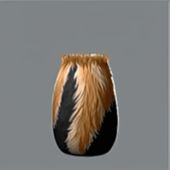
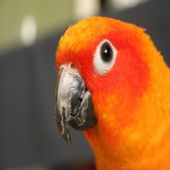
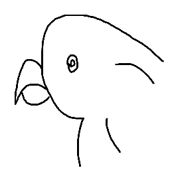
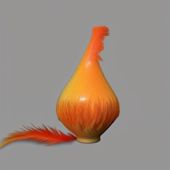
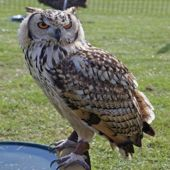
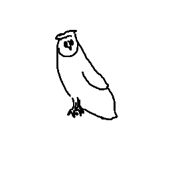
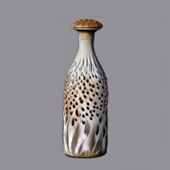

In [ ]:
clean = df[df.passed & df.seg_ok]
g3 = clean.sample(min(20, len(clean)), random_state=1).index
sheet(g3)

## Your decisions (the only cell you have to edit)
Put the `row` numbers you looked at into these sets. Leave them empty to keep the conservative default (only rows that passed the filters **and** have a real segmentation).

In [ ]:
APPROVE_FALLBACK = set()   # passed filters, seg_ok=False, but the reference looks right -> keep
APPROVE_FAILED   = set()   # failed filters but looks fine to you -> keep
DROP             = set()   # passed everything but looks wrong to you -> drop

# ap = df.row.isin(APPROVE_FALLBACK | APPROVE_FAILED)
# df['keep'] = ((df.passed & df.seg_ok) | ap) & ~df.row.isin(DROP)
# df['manually_approved'] = ap & df.keep
# df['drop_reason'] = np.select(
#     [df.row.isin(DROP), ~df.passed & ~ap, df.passed & ~df.seg_ok & ~ap],
#     ['manual_drop', 'failed_filters', 'unverified_segmentation'], default='')
# print('keeping', int(df.keep.sum()), 'of', len(df)); print(df[~df.keep].drop_reason.value_counts().to_string())
df['keep'] = True
df['manually_approved'] = True
df['drop_reason'] = ''

kept = df[df.keep]
kept = df[df.keep]
assert kept.ref_file.notna().all() and kept.mask_file.notna().all(), 'a kept row has no reference/mask file'
assert kept.photo_file.map(os.path.exists).all() and kept.sketch_file.map(os.path.exists).all()

## Alignment check
The whole sketch-control pathway assumes the sketch lies exactly on the photo. Sketchy sketches were drawn over a **square-resized** version of each photo, so the photo is squashed (not cropped) to a square here. The strip below overlays the sketch strokes in red on the photo: **the strokes must sit on the object outlines.** If they are systematically shifted or scaled, stop and tell me before training anything.

photo sizes : [((256, 256), 200)]
sketch sizes: [((256, 256), 200)]


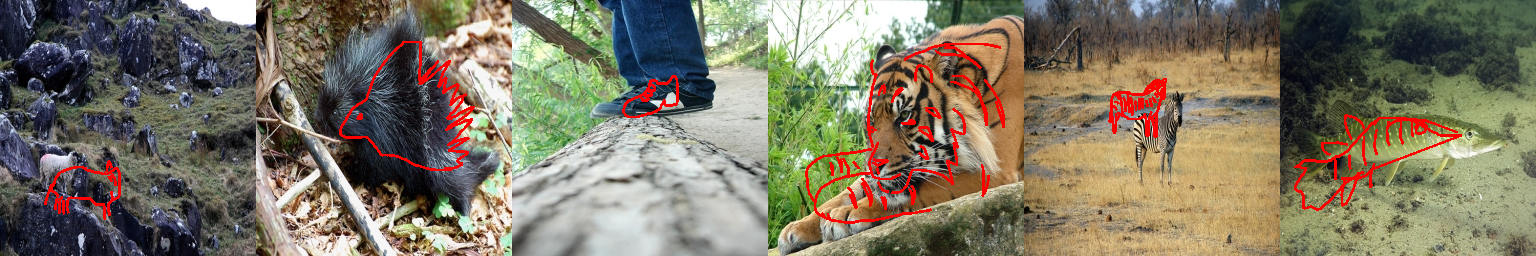

In [ ]:
print('photo sizes :', Counter(Image.open(p).size for p in kept.photo_file).most_common(5))
print('sketch sizes:', Counter(Image.open(p).size for p in kept.sketch_file).most_common(5))

def white_bg(im):
    if im.mode in ('RGBA', 'LA') or 'transparency' in im.info:
        im = im.convert('RGBA'); bg = Image.new('RGBA', im.size, (255, 255, 255, 255)); bg.alpha_composite(im); im = bg
    return im.convert('L')

def overlay(r, size=256):
    ph = np.asarray(Image.open(r.photo_file).convert('RGB').resize((size, size), Image.LANCZOS)).copy()
    sk = np.asarray(white_bg(Image.open(r.sketch_file)).resize((size, size), Image.BICUBIC)) < 128
    ph[sk] = (255, 0, 0)
    return Image.fromarray(ph)

strip = Image.new('RGB', (256 * 6, 256))
for k, (_, r) in enumerate(kept.sample(min(6, len(kept)), random_state=0).iterrows()):
    strip.paste(overlay(r), (256 * k, 0))
display(strip)

## Build `pilot_v1`
Writes `target/ sketch/ reference/ mask/` (all `RES x RES`), `metadata.jsonl`, `manifest.json`, `dropped.csv`. Sketches are normalised to **black strokes on white** (transparent PNGs are composited on white first). Masks are for evaluation only (layout IoU, later the spatial conflicts); they are never a model input.

In [ ]:
shutil.rmtree(OUT, ignore_errors=True)
for d in ['target', 'sketch', 'reference', 'mask']:
    os.makedirs(f'{OUT}/{d}')

# split BY PHOTO (never by sketch), fixed seed
photos = np.array(sorted(kept.photo_file.unique()))
rng = np.random.RandomState(SEED); rng.shuffle(photos)
n_test = max(1, round(TEST_FRAC * len(photos))); n_val = max(1, round(VAL_FRAC * len(photos)))
split_of = {p: 'test' for p in photos[:n_test]}
split_of.update({p: 'val' for p in photos[n_test:n_test + n_val]})
split_of.update({p: 'train' for p in photos[n_test + n_val:]})

records = []
for _, r in kept.iterrows():
    sid = f'{r.row:04d}'
    Image.open(r.photo_file).convert('RGB').resize((RES, RES), Image.LANCZOS).save(f'{OUT}/target/{sid}.png')
    sk = white_bg(Image.open(r.sketch_file))
    if np.asarray(sk).mean() < 127:                      # white strokes on black -> flip to black on white
        sk = Image.eval(sk, lambda v: 255 - v)
    sk.convert('RGB').resize((RES, RES), Image.BICUBIC).save(f'{OUT}/sketch/{sid}.png')
    Image.open(r.ref_file).convert('RGB').resize((RES, RES), Image.LANCZOS).save(f'{OUT}/reference/{sid}.png')
    m = (np.asarray(Image.open(r.mask_file).convert('L')) > 127).astype(np.uint8) * 255
    Image.fromarray(m).resize((RES, RES), Image.NEAREST).save(f'{OUT}/mask/{sid}.png')
    records.append(dict(
        id=sid, row=int(r.row), category=str(r.category), caption=str(r.caption).strip(),
        target=f'target/{sid}.png', sketch=f'sketch/{sid}.png', reference=f'reference/{sid}.png', mask=f'mask/{sid}.png',
        split=split_of[r.photo_file],
        # how the reference was made (kept for the report / debugging)
        ref_colors='' if pd.isna(r.colors) else str(r.colors), ref_material='' if pd.isna(r.material) else str(r.material),
        ref_finish='' if pd.isna(r.finish) else str(r.finish), ref_object=str(r.ref_object), ref_prompt=str(r.prompt),
        ref_dino_sim=float(r.dino_sim), ref_color_dist=float(r.color_dist),
        ref_filters_passed=bool(r.passed), seg_ok=bool(r.seg_ok), manually_approved=bool(r.manually_approved),
        # conflict-aware tagging (presentation: preprocessing step 3)
        conflict_type='none', geometry_src='sketch', semantics_src='text', appearance_src='reference'))
print(len(records), 'samples written', dict(Counter(x['split'] for x in records)))

200 samples written {'train': 160, 'val': 20, 'test': 20}


In [ ]:
with open(f'{OUT}/metadata.jsonl', 'w') as f:
    for rec in records:
        f.write(json.dumps(rec) + '\n')

dropped = df[~df.keep][['row', 'category', 'drop_reason', 'dino_sim', 'color_dist', 'n_obj', 'seg_ok']]
dropped.to_csv(f'{OUT}/dropped.csv', index=False)

manifest = dict(
    version='pilot_v1', frozen_at=datetime.datetime.now().isoformat(timespec='seconds'), resolution=RES, seed=SEED,
    split_unit='photo', counts=dict(source_rows=len(df), kept=len(records), **dict(Counter(x['split'] for x in records))),
    dropped_by_reason=dropped.drop_reason.value_counts().to_dict(),
    approved_fallback=sorted(int(i) for i in APPROVE_FALLBACK), approved_failed=sorted(int(i) for i in APPROVE_FAILED),
    manual_drop=sorted(int(i) for i in DROP),
    metadata_sha256=hashlib.sha256(open(f'{OUT}/metadata.jsonl', 'rb').read()).hexdigest(),
    sketch_polarity='black strokes on white', photo_to_square='squash resize (matches how Sketchy sketches were drawn)',
    conflict_subset='not built yet: all rows have conflict_type=none')
json.dump(manifest, open(f'{OUT}/manifest.json', 'w'), indent=2)

# verify, then ship ONE zip to Drive
for rec in records:
    for k in ['target', 'sketch', 'reference', 'mask']:
        assert Image.open(f"{OUT}/{rec[k]}").size == (RES, RES), (rec['id'], k)
shutil.make_archive('/content/pilot_v1', 'zip', OUT)
shutil.copy('/content/pilot_v1.zip', OUT_ZIP)
print(json.dumps(manifest['counts']), '\nsaved ->', OUT_ZIP)

{"source_rows": 200, "kept": 200, "train": 160, "val": 20, "test": 20} 
saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/pilot_v1.zip


**Next:** `02_unicombine_pipeline.ipynb` (needs a big-memory GPU: see the note at the top of that notebook).